# Introduction to the Concrete Dataset¶
### For our deep learning journey, we will work with a real-world dataset:
### Concrete Compressive Strength dataset.
🔹 What's inside this dataset?

### 8 input features related to the material composition and age of concrete:
- **Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age (days).**
### 1 output feature (target):
- **Concrete Compressive Strength (in Megapascals, MPa)**

# 🔵 Why is this dataset important?

- **Concrete is the most important construction material in civil engineering.**
- **The strength of concrete depends on complex, nonlinear relationships between ingredients and curing time.**
- **Predicting compressive strength accurately helps in designing stronger, safer structures.**

## Import Necessary Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import warnings
warnings.filterwarnings("ignore")


In [2]:
# Load the Concrete_Data.csv dataset
data = pd.read_csv("Concrete_Data.csv")

# Show shape of the dataset
print("Shape of the dataset:", data.shape)

# Display first few rows
data.head()

Shape of the dataset: (1030, 9)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [3]:
col_names=data.columns.to_list()
print("All columns Names:", col_names)

All columns Names: ['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


## Missing Values Check

In [4]:
data.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

# Basic Visualization

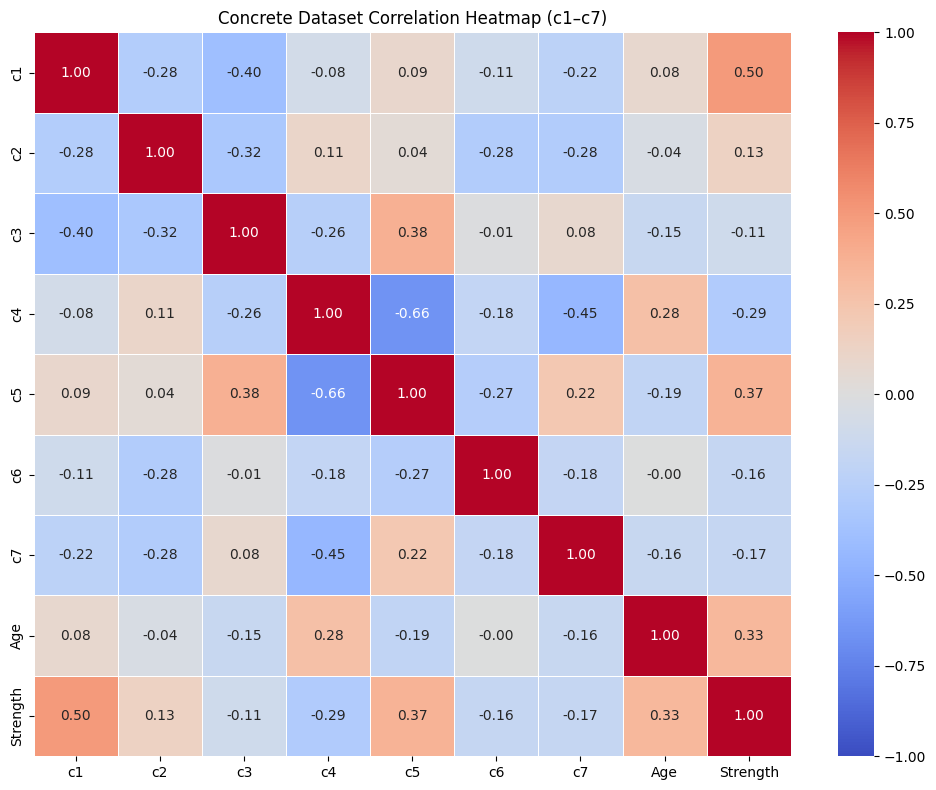

In [5]:
# 2. Rename the 7 components to c1-c7 (and shorten Age & Strength)
data.columns = ["c1", "c2", "c3", "c4", "c5", "c6", "c7", "Age", "Strength"]

# 3. Compute the correlation matrix
corr_matrix = data.corr()

# 4. Draw the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Concrete Dataset Correlation Heatmap (c1–c7)")
plt.tight_layout()
plt.show()


In [6]:
# import torch

# # Convert inputs and targets to PyTorch tensors
# inputs_tensor = torch.tensor(inputs.values, dtype=torch.float32)
# targets_tensor = torch.tensor(targets.values, dtype=torch.float32)

# # Check their shapes
# print("Inputs Tensor Shape:", inputs_tensor.shape)
# print("Targets Tensor Shape:", targets_tensor.shape)


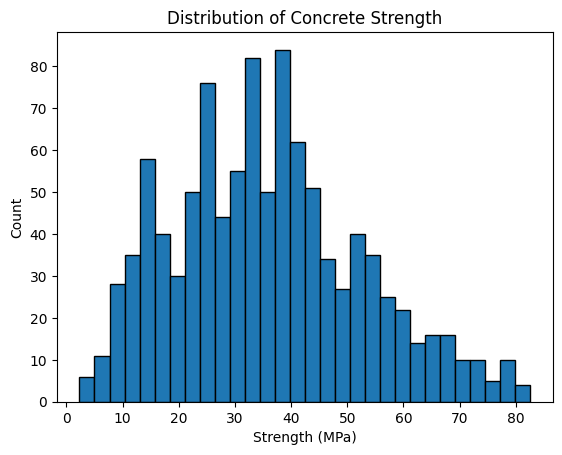

In [7]:
# Plot histogram for the target variable (Concrete Strength)
plt.hist(data.iloc[:, -1], bins=30, edgecolor='k')
plt.title('Distribution of Concrete Strength')
plt.xlabel('Strength (MPa)')
plt.ylabel('Count')
plt.show()

# Define inputs and target

In [8]:
# Inputs: all columns except the last one
inputs = data.iloc[:, :-1].values

# Targets: only the last column
targets = data.iloc[:, -1].values.reshape(-1, 1) 

print("Input shape:", inputs.shape)
print("Target shape:", targets.shape)

Input shape: (1030, 8)
Target shape: (1030, 1)


# Shuffle and split FIRST (on raw numpy data)

In [9]:
torch.manual_seed(42)
n_samples = inputs.shape[0]
indices = torch.randperm(n_samples).numpy()
split_idx = int(n_samples * 0.8)

train_indices = indices[:split_idx]
test_indices = indices[split_idx:]

X_train_raw, X_test_raw = inputs[train_indices], inputs[test_indices]
y_train_raw, y_test_raw = targets[train_indices], targets[test_indices]

# Fit scaler on TRAIN only, apply to both

In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Convert to PyTorch tensors

In [12]:
X_train = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train = torch.tensor(y_train_raw, dtype=torch.float32)
y_test = torch.tensor(y_test_raw, dtype=torch.float32)

# Initialize model parameters

In [13]:
num_features = X_train.shape[1]  # Should be 8
W = torch.randn((num_features, 1), requires_grad=True)
W.data *= 0.01  # Scale down initial values
b = torch.zeros((1,), requires_grad=True)

# 7. Confirm everything is set up
print("Training set size:", X_train.shape[0])
print("Test set size:", X_test.shape[0])
print("Weight shape:", W.shape)
print("Bias shape:", b.shape)

Training set size: 824
Test set size: 206
Weight shape: torch.Size([8, 1])
Bias shape: torch.Size([1])
